In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import linkage


First we import functions for computing entropy

In [2]:
%run "predictability-functions.ipynb"

We then
- Load the ParaCzech forms of interest
- Load the corresponding lexemes file
- Add gender information as an extra column in the forms file
- Adapt the format of `orth_form` so that is can be input to `alt`

Note that paths to `paraczech_forms.csv` and `paraczech_lexemes.csv` may need to be adapted to your configuration.

In [ ]:
df = pd.read_csv('paraczech/paraczech_forms.csv',index_col=0)
lex = pd.read_csv('paraczech/paraczech_lexemes.csv',index_col=0)

gen = lex.gender.to_dict()
df['gender'] = df.lexeme.apply(lambda s: gen[s] if s in gen else None)

# This is needed so that we can use the same code for orthography and phonology

df['orth_form'] = df.orth_form.apply(lambda x:' '.join(list(x)).replace('c h','ch'))

df.sample(5)

,lexeme,cell,phon_form,candidate_phon_form,orth_form,overabundance_tag,UCNK,frequency,frequency_per_million,gender
form_id,,,,,,,,,,
f2400501,makak,ins.sg,m a k a k ɛ m,NaN,m a k a k e m,NaN,NNMS7-----A----,47,0.009960,m.anim
f4456716,přetlumočení,dat.sg,p r̝̊ ɛ t l u m ɔ t͡ʃ ɛ ɲ iː,NaN,p ř e t l u m o č e n í,NaN,NNNS3-----A----,31,0.006569,n
f79096,anděl,loc.sg,ʔ a n ɟ ɛ l ɔ v ɪ,NaN,a n d ě l o v i,NaN,NNMS6-----A----,301,0.063785,m.anim
f8128168,šedina,ins.sg,ʃ ɛ ɟ ɪ n ɔu̯,NaN,š e d i n o u,NaN,NNFS7-----A----,14,0.002967,f
f2916714,natahovač,dat.pl,n a t a ɦ ɔ v a t͡ʃ uː m,NaN,n a t a h o v a č ů m,NaN,NNIP3-----A----,1,0.000212,m.inan


This is needed for ordering cells

In [4]:
cells = ['nom.sg',
 'gen.sg',
 'dat.sg',
 'acc.sg',
 'loc.sg',
 'ins.sg',
 'nom.pl',
 'gen.pl',
 'dat.pl',
 'acc.pl',
 'loc.pl',
 'ins.pl']

Now we can compute conditional entropy between all pairs of cells, on the basis of phonemes or graphemes, and with or without conditioning on gender.

This will take a few minutes.

In [5]:
results = []
for cell1 in cells:
    for cell2 in cells:
        if cell1!=cell2:
            print(cell1,'→',cell2, end=' ')
            results.append((cell1,cell2,
                        cond_ent(cell1,cell2,df,'phon')['entropy'],
                        cond_ent(cell1,cell2,df,'orth')['entropy'],
                        cond_ent_plus(cell1,cell2,'gender',df,'phon')['entropy'],
                        cond_ent_plus(cell1,cell2,'gender',df,'orth')['entropy'],
                       ))
    print()
print("Done!")

results = pd.DataFrame(res,columns=['predictor','target','phon','orth','phon_gender','orth_gender'])
results.set_index(['predictor','target'],inplace=True)


nom.sg → gen.sg nom.sg → dat.sg nom.sg → acc.sg nom.sg → loc.sg nom.sg → ins.sg nom.sg → nom.pl nom.sg → gen.pl nom.sg → dat.pl nom.sg → acc.pl nom.sg → loc.pl nom.sg → ins.pl 
gen.sg → nom.sg gen.sg → dat.sg gen.sg → acc.sg gen.sg → loc.sg gen.sg → ins.sg gen.sg → nom.pl gen.sg → gen.pl gen.sg → dat.pl gen.sg → acc.pl gen.sg → loc.pl gen.sg → ins.pl 
dat.sg → nom.sg dat.sg → gen.sg dat.sg → acc.sg dat.sg → loc.sg dat.sg → ins.sg dat.sg → nom.pl dat.sg → gen.pl dat.sg → dat.pl dat.sg → acc.pl dat.sg → loc.pl dat.sg → ins.pl 
acc.sg → nom.sg acc.sg → gen.sg acc.sg → dat.sg acc.sg → loc.sg acc.sg → ins.sg acc.sg → nom.pl acc.sg → gen.pl acc.sg → dat.pl acc.sg → acc.pl acc.sg → loc.pl acc.sg → ins.pl 
loc.sg → nom.sg loc.sg → gen.sg loc.sg → dat.sg loc.sg → acc.sg loc.sg → ins.sg loc.sg → nom.pl loc.sg → gen.pl loc.sg → dat.pl loc.sg → acc.pl loc.sg → loc.pl loc.sg → ins.pl 
ins.sg → nom.sg ins.sg → gen.sg ins.sg → dat.sg ins.sg → acc.sg ins.sg → loc.sg ins.sg → nom.pl ins.sg → gen.pl ins

# 3.4 Results 
## 3.4.1 Overall predictability from phonological forms

Mean predictability:

In [6]:
res.phon.mean()

0.43312976700133754

Extreme values of entropy:

In [7]:
res.sort_values('phon')

,,phon,orth,phon_gender,orth_gender
predictor,target,,,,
loc.sg,dat.sg,0.022556,0.022808,0.007791,0.007789
dat.sg,loc.sg,0.040649,0.041033,0.025814,0.026371
nom.pl,acc.pl,0.047754,0.061422,0.022225,0.022623
ins.sg,ins.pl,0.086468,0.197720,0.035083,0.105980
dat.sg,loc.pl,0.093656,0.152298,0.072831,0.115386
...,...,...,...,...,...
acc.pl,gen.pl,0.907586,0.983176,0.246345,0.292727
dat.pl,acc.sg,0.949318,0.899234,0.282352,0.309494
loc.pl,nom.pl,0.975455,0.902358,0.128213,0.125441


The following functions are used to produce a heatmap with cells that are more interpredictable closer to one another. This is done by producing a seaborn `clustermap` with a custom linkage, and hiding the dendrograms.

In [8]:

def averages(S,cells):
    res = {}
    for i in range(len(cells)-1):
        for j in range(i+1,len(cells)):
            res[(cells[i],cells[j])] = (S[(cells[i],cells[j])] + S[(cells[j],cells[i])])/2
    return pd.Series(res)


def my_clustermap(df,col):
    newdf = df[[col]].reset_index().pivot(columns="target",index="predictor",values=col)
    newdf = newdf.loc[cells,cells]
    link = linkage(averages(df[col],cells))
    f = sns.clustermap(newdf,
            annot=True,
            row_linkage = link,
            col_linkage = link,
#            cmap = sns.color_palette("Blues", as_cmap=True),
            cmap = sns.cubehelix_palette(start=.5, rot=-.75, as_cmap=True),
            cbar_pos = None,
            vmin = 0,
            figsize=(8,8)
                  )
    f.ax_col_dendrogram.set_visible(False)
    f.ax_row_dendrogram.set_visible(False)
    ax = f.ax_heatmap
    ax.tick_params(left=True,right=False,labelleft=True,labelright=False)
    ax.tick_params(top = True, bottom = False, labeltop=True, labelbottom=False, labelrotation=False)
    ax.set_xticklabels(ax.get_xticklabels(), rotation = 90)
    f.ax_col_dendrogram.set_visible(False)
    return f

Figure 4:

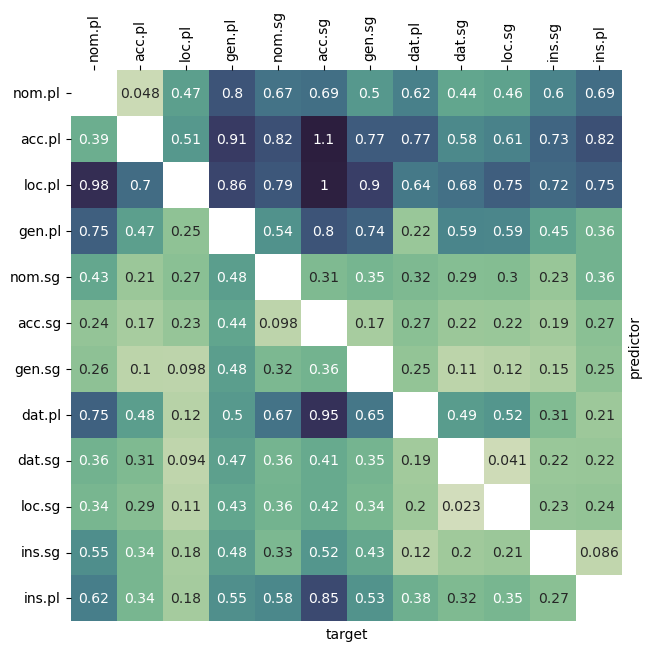

In [9]:
f = my_clustermap(res, 'phon')
f.savefig('../paper-overleaf/images/heatmap-no-gender.pdf')

Figure 5:

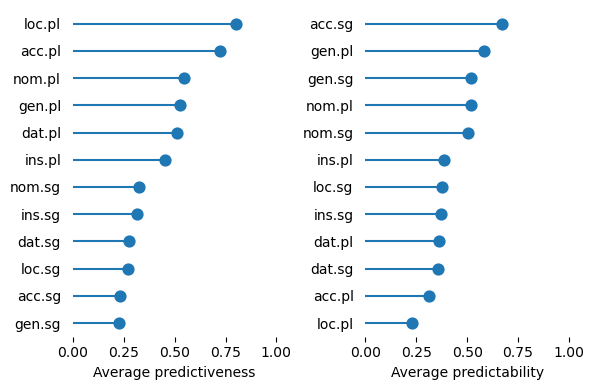

In [10]:
aux = res.reset_index()
predictiveness = aux.groupby('predictor').agg({'phon':'mean','phon_gender':'mean'}).sort_values('phon',ascending=False).reset_index()
predictiveness
predictability = aux.groupby('target').agg({'phon':'mean','phon_gender':'mean'}).sort_values('phon',ascending=False).reset_index()

fig,ax = plt.subplots(1,2,figsize=(6,4))

for i in predictiveness.index:
    ax[0].axhline(i,0, predictiveness.at[i,'phon'])

for i in predictability.index:
    ax[1].axhline(i,0, predictability.at[i,'phon'])

sns.pointplot(predictiveness,y='predictor',x='phon',
                  linestyle='none',
                  errorbar=None,
                  ax=ax[0]
             )
sns.pointplot(predictability,y='target',x='phon',
                  linestyle='none',
                  errorbar=None,
                  ax=ax[1]
             )

for i in (0,1):
    ax[i].set(ylabel=None)
    ax[i].tick_params('y', length=5)
    ax[i].grid(False)
    ax[i].set(xlim=(0,1))
    ax[i].tick_params(left=False)


ax[0].set(xlabel='Average predictiveness')
ax[1].set(xlabel='Average predictability')
    

plt.tight_layout()
sns.despine(left=True, bottom=True)

fig.savefig('../paper-overleaf/images/predictability-predictiveness.pdf')

phon      orth  phon_gender  orth_gender
predictor target                                              
nom.sg    gen.sg  0.347446  0.498874     0.166702     0.119495
          dat.sg  0.289842  0.418618     0.182489     0.124280
          acc.sg  0.309170  0.358596     0.025613     0.019452
          loc.sg  0.297670  0.440288     0.187401     0.139059
          ins.sg  0.225878  0.345877     0.145346     0.087580
...                    ...       ...          ...          ...
ins.pl    nom.pl  0.624025  0.520025     0.057412     0.031771
          gen.pl  0.550180  0.544762     0.270935     0.316838
          dat.pl  0.384063  0.094022     0.095285     0.015024
          acc.pl  0.340937  0.226789     0.050322     0.012387
          loc.pl  0.178585  0.069347     0.086981     0.052786

[132 rows x 4 columns]

## 3.4.2 Phonology vs. orthography
Figure 6:

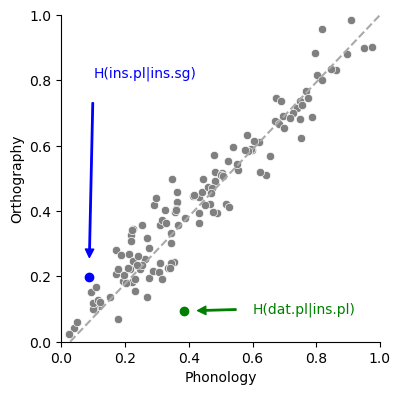

In [38]:
g = sns.relplot(results,x='phon',y='orth',height=4,aspect = 1,color='gray')
g.set(xlim=(0,1),ylim=(0,1),xlabel='Phonology',ylabel='Orthography')
axes = g.axes.flatten()
for ax in axes:
    ax.axline((0,-0.0281),(1,1),linestyle='dashed',color='darkgray')
    ax.annotate('H(dat.pl|ins.pl)',
            xy=(results.at[('ins.pl', 'dat.pl'),'phon'],results.at[('ins.pl', 'dat.pl'),'orth']), xycoords='data',
            xytext=(.6, 0.1), textcoords='data', color = 'green',
            arrowprops=dict(color='green', shrink=0.2, width = 1, headwidth=6, headlength = 6),
            horizontalalignment='left', verticalalignment='center')
    ax.annotate('H(ins.pl|ins.sg)',
            xy=(results.at[('ins.sg', 'ins.pl'),'phon'],results.at[('ins.sg', 'ins.pl'),'orth']), xycoords='data',
            xytext=(.1, 0.8), textcoords='data', color='blue',
            arrowprops=dict(color='blue', shrink=0.1, width = 1, headwidth=6, headlength = 6),
            horizontalalignment='left', verticalalignment='bottom')

plt.plot(results.at[('ins.pl', 'dat.pl'),'phon'],results.at[('ins.pl', 'dat.pl'),'orth'],'go')
plt.plot(results.at[('ins.sg', 'ins.pl'),'phon'],results.at[('ins.sg', 'ins.pl'),'orth'],'bo')
g.savefig('../paper-overleaf/images/ortho-relplot.pdf')

Correlation between entropy values found with orthographic vs. phonological transcriptions

In [32]:
results[['phon','orth']].corr().iloc[0,1]

0.9591075658145325

Slope of a linear model relating entropy values found with orthographic vs. phonological transcriptions

In [13]:
import statsmodels.formula.api as smf
fit = smf.ols('orth ~ phon',data=results).fit()
fit.params

Intercept    0.017444
phon         0.955324
dtype: float64

### Comparison: INS.SG predicting INS.PL

In [33]:
results.loc[('ins.sg','ins.pl'),['phon','orth']]

phon    0.086468
orth    0.197720
Name: (ins.sg, ins.pl), dtype: float64

Nouns with a stem ending in an ambiguous consonant
and taking the suffix _-em_ in the INS.SG:

In [15]:
def test(s):
    l = s.split(' ')
    if s.endswith('e m') and l[-3] in orth_segments['ambiguous']:
        return True
    

pairs = df[df.cell.isin(['ins.sg','ins.pl'])].pivot_table(columns="cell",index="lexeme",values="orth_form",aggfunc = lambda l:';'.join(l))
pairs = pairs.dropna()
pairs = pairs[(~pairs['ins.sg'].str.contains(';'))& (~pairs['ins.pl'].str.contains(';'))]
subset = pairs[(pairs['ins.sg'].notna()) & (pairs['ins.sg'].apply(test))]
subset

cell,ins.pl,ins.sg
lexeme,,
akcíz,a k c í z y,a k c í z e m
anděl,a n d ě l y,a n d ě l e m
apoštol,a p o š t o l y,a p o š t o l e m
arab,a r a b y,a r a b e m
archanděl,a r ch a n d ě l y,a r ch a n d ě l e m
...,...,...
životopis,ž i v o t o p i s y,ž i v o t o p i s e m
živočichopis,ž i v o č i ch o p i s y,ž i v o č i ch o p i s e m
žlab,ž l a b y,ž l a b e m


Among these nouns , _y_ in the INS.PL is the strongly preferred option:

In [16]:
subset['alt'] = subset.apply(lambda S:alt(S['ins.sg'],S['ins.pl'],orth_segments),axis=1)
subset.alt.value_counts(normalize=True)

/var/folders/q1/4q3cyfvn3vn8v9zx1hdty8xr0000gp/T/ipykernel_1674/3755868437.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  subset['alt'] = subset.apply(lambda S:alt(S['ins.sg'],S['ins.pl'],orth_segments),axis=1)


alt
A e m ~ A y                    0.799302
A e m ~ A i                    0.197789
V z e m ~ V ž í m i            0.001745
S í t e l e m ~ S á t e l i    0.001163
Name: proportion, dtype: float64

These nouns are only 10% of the data:

In [17]:
len(subset)/len(pairs)

0.10182442838526241

### Comparison: INS.PL predicting DAT.PL

In [34]:
results.loc[('ins.pl','dat.pl'),['phon','orth']]

phon    0.384063
orth    0.094022
Name: (ins.pl, dat.pl), dtype: float64

## 3.4.3 The role of gender
Figure 7

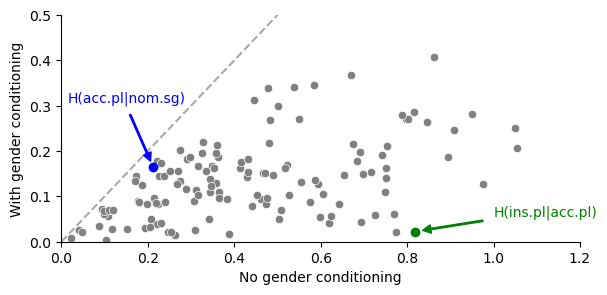

In [37]:
g = sns.relplot(results,x='phon',y='phon_gender',height=3,aspect = 2,color='gray')
g.set(xlim=(0,1.2),ylim=(0,.5),xlabel='No gender conditioning',ylabel='With gender conditioning')

axes = g.axes.flatten()
for ax in axes:
    ax.axline((0,0),(1,1),linestyle='dashed',color='darkgray')
    ax.annotate('H(ins.pl|acc.pl)',
            xy=(results.at[('acc.pl', 'ins.pl'),'phon'],results.at[('acc.pl', 'ins.pl'),'phon_gender']), xycoords='data',
            xytext=(1, 0.05), textcoords='data', color = 'green',
            arrowprops=dict(color='green', shrink=0.1, width = 1, headwidth=6, headlength = 6),
            horizontalalignment='left', verticalalignment='bottom')
    ax.annotate('H(acc.pl|nom.sg)',
            xy=(results.at[('nom.sg', 'acc.pl'),'phon'],results.at[('nom.sg', 'acc.pl'),'phon_gender']), xycoords='data',
            xytext=(.15, 0.3), textcoords='data', color='blue',
            arrowprops=dict(color='blue', shrink=0.1, width = 1, headwidth=6, headlength = 6),
            horizontalalignment='center', verticalalignment='bottom')
plt.plot(results.at[('acc.pl', 'ins.pl'),'phon'],results.at[('acc.pl', 'ins.pl'),'phon_gender'],'go')
plt.plot(results.at[('nom.sg', 'acc.pl'),'phon'],results.at[('nom.sg', 'acc.pl'),'phon_gender'],'bo')
#plt.plot(res.at[('nom.sg', 'gen.sg'),'phon'],res.at[('nom.sg', 'gen.sg'),'phon_gender'],'bo')

g.savefig('../paper-overleaf/images/gender-relplot.pdf')

Minimum value

In [39]:
results.phon_gender.min()

0.0027673647180905554

Comparing averages

In [40]:
results[['phon','phon_gender']].mean()

phon           0.433130
phon_gender    0.136381
dtype: float64

Extreme ratios between prediction without and with gender

In [41]:
results['ratio'] = (results.phon/results.phon_gender)
results[['phon','phon_gender','ratio']].sort_values('ratio')

phon  phon_gender      ratio
predictor target                                  
acc.sg    gen.sg  0.172323     0.143907   1.197463
          loc.sg  0.221934     0.177794   1.248265
          acc.pl  0.170151     0.134975   1.260609
          dat.sg  0.218107     0.171691   1.270341
dat.sg    loc.pl  0.093656     0.072831   1.285928
...                    ...          ...        ...
gen.sg    nom.pl  0.262518     0.015033  17.462777
acc.pl    nom.pl  0.387825     0.017767  21.828949
          ins.pl  0.817466     0.022353  36.570571
gen.sg    acc.pl  0.102985     0.002767  37.214211
acc.pl    dat.pl  0.774133     0.020512  37.739751

[132 rows x 3 columns]

### Comparison: ACC.PL predicting INS.PL

In [42]:
results.loc[('acc.pl','ins.pl'),['phon','phon_gender']]

phon           0.817466
phon_gender    0.022353
Name: (acc.pl, ins.pl), dtype: float64

Table 14:

In [44]:
def test(s):
    l = s.split(' ')
    if s.endswith('e m') and l[-3] in orth_segments['ambiguous']:
        return True

# For purposes of this table we abstract away the class of stem-final segment
def simple_alt(x,y,segments):
    the_alt = alt(x,y,segments).split(' ~ ')
    if len(the_alt)==2:
        if the_alt[0][0]==the_alt[1][0] and the_alt[0][0] in ['A','H','I','V']:
            return the_alt[0][2:]+' ~ '+the_alt[1][2:]

pairs = df[df.cell.isin(['acc.pl','ins.pl'])].pivot_table(columns="cell",index="lexeme",values="phon_form",aggfunc = lambda l:';'.join(l))
pairs = pairs.dropna()
pairs = pairs[(~pairs['acc.pl'].str.contains(';'))& (~pairs['ins.pl'].str.contains(';'))]
pairs['alt'] = pairs.apply(lambda S:simple_alt(S['acc.pl'],S['ins.pl'],phon_segments),axis=1)
pairs['ending'] = pairs['acc.pl'].apply(lambda s: s.split(' ')[-1])
pairs['gender'] = pairs.apply(lambda S:gen[S.name],axis=1)

total = len(pairs)

excluded = 0

# First we exclude situations of stem allomorphy. There is juste one, with the pattern "c ɪ ~ t m ɪ"

excluded+=len(pairs[pairs.alt == "c ɪ ~ t m ɪ"])
pairs = pairs[pairs.alt!="c ɪ ~ t m ɪ"]

#Then we exclude low frequency endings

the_endings = pairs.ending.value_counts()
the_endings = the_endings[the_endings>=100].index.to_list()

excluded += len(pairs[~pairs.ending.isin(the_endings)]) 

pairs = pairs[pairs.ending.isin(the_endings)]

l = []
for i, group in pairs.groupby('ending'):
    table = group.alt.value_counts()
    excluded += len(table[table<20])
    table = table[table>=20]
    table = pd.DataFrame(table)
    table.columns=["Overall"]
    for gender in ["m.anim", "m.inan", "f", "n"]:
        for j in table.index:
            n  = len(group[(group.alt==j) & (group.gender==gender)])
            if n < 20:
                table.at[j,gender] = '---'
                excluded +=n
            else:
                table.at[j,gender] = str(int(n))
    table["Ending"] = i
    table["Group_total"] = len(group)
    table = table.reset_index()
    table=table[["Ending",'alt',"Overall","m.anim", "m.inan", "f", "n","Group_total"]]
    l.append(table)

table = pd.concat(l)

table = table.sort_values(["Group_total","Overall"],ascending=False)

table = table.drop("Group_total",axis=1)
table = table.set_index(["Ending","alt"])

display(table)

print(excluded, ' datapoints excluded (',round(100*excluded/total,2),"%)",sep="")



Overall m.anim m.inan     f     n
Ending alt                                         
ɪ       ~            5600   1650   3942   ---   ---
       ɪ ~ a m ɪ     4671    ---    ---  4671   ---
ɛ       ~ m ɪ        1122    ---    ---  1122   ---
       ɛ ~ ɪ          342    327    ---   ---   ---
iː      ~ m ɪ        1482    ---    ---   ---  1480
a      a ~ ɪ          858    ---    ---   ---   858

408 datapoints excluded (2.43%)


### Comparison: NOM.SG predicting ACC.PL

In [88]:
results.loc[('nom.sg','acc.pl'),['phon','phon_gender']]

phon           0.212623
phon_gender    0.164021
Name: (nom.sg, acc.pl), dtype: float64

Table 15:

In [89]:
def nom_sg_ending(s,segments):
    l = s.split(' ')
    if l[-1] in segments['hard']:
        return "Hard C."
    if l[-1] in segments['soft']:
        return "Soft C."
    if l[-1] in segments['ambiguous']:
        return "Ambiguous C."
    return l[-1]

def acc_pl_expo(S,segments):
    if S['acc.pl'].endswith('a t a'):
        return 'ata'
    return S['acc.pl'].split(' ')[-1]

pairs = df[df.cell.isin(['nom.sg','acc.pl'])].pivot_table(columns="cell",index="lexeme",values="phon_form",aggfunc = lambda l:';'.join(l))
pairs = pairs.dropna()
pairs = pairs[(~pairs['nom.sg'].str.contains(';'))& (~pairs['acc.pl'].str.contains(';'))]
pairs['gender'] = pairs.apply(lambda S:gen[S.name],axis=1)
pairs["nom.sg ending"] = pairs["nom.sg"].apply(lambda s:nom_sg_ending(s,phon_segments))
pairs["acc.pl expo"] = pairs.apply(lambda S:acc_pl_expo(S,phon_segments),axis=1)
pairs['alt'] = pairs.apply(lambda S:simple_alt(S['nom.sg'],S['acc.pl'],phon_segments),axis=1)


total = len(pairs)

excluded = 0


the_endings = pairs['nom.sg ending'].value_counts()
the_endings = the_endings[the_endings>=100].index.to_list()

#the_expos = pairs['acc.pl expo'].value_counts()
#the_expos = the_expos[the_expos>=100].index.to_list()

excluded += len(pairs[~pairs['nom.sg ending'].isin(the_endings)]) 
#excluded += len(pairs[~pairs['acc.pl expo'].isin(the_expos)]) 


pairs = pairs[(pairs['nom.sg ending'].isin(the_endings))]
#pairs = pairs[(pairs['acc.pl expo'].isin(the_expos))]



l = []
for i, group in pairs.groupby('nom.sg ending'):
    table = group["acc.pl expo"].value_counts()
    excluded += len(table[table<20])
    table = table[table>=20]
    table = pd.DataFrame(table)
    table.columns=["Overall"]
    for gender in ["m.anim", "m.inan", "f", "n"]:
        for j in table.index:
            n  = len(group[(group["acc.pl expo"]==j) & (group.gender==gender)])
            if n < 20:
                table.at[j,gender] = '---'
                excluded +=n
            else:
                table.at[j,gender] = str(int(n))
    table["Ending"] = i
    table["Group_total"] = len(group)
    table = table.reset_index()
    table=table[["Ending","acc.pl expo","Overall","m.anim", "m.inan", "f", "n","Group_total"]]
    l.append(table)

table = pd.concat(l)

table = table.sort_values(["Group_total","Overall"],ascending=False)

table = table.drop("Group_total",axis=1)
table = table.set_index(["Ending","acc.pl expo"])

display(table)

print(excluded, ' datapoints excluded (',round(100*excluded/total,2),"%)",sep="")



Overall m.anim m.inan     f     n
Ending       acc.pl expo                                   
a            ɪ               5605    115    ---  5490   ---
Hard C.      ɪ               5392   1485   3286   621   ---
iː           iː              4320    ---    ---   ---  4316
Soft C.      ɛ               2448   1506    718   224   ---
             ɪ                 53    ---    ---    45   ---
Ambiguous C. ɪ               1160    158    994   ---   ---
             ɛ                407    352    ---    39   ---
ɛ            ɛ               1306    108    ---  1042   155
             ata               74    ---    ---   ---    74
ɔ            a                859    ---    ---   ---   858

142 datapoints excluded (0.65%)


Table 16: Voicing alternations

In [131]:
voicing_pairs = [('p', 'b'), ('t', 'd'), ('c', 'ɟ'), ('k', 'ɡ'), ('f', 'v'), ('s', 'z'), ('ʃ', 'ʒ'), ('x', 'ɦ'), ('t͡s', 'd͡z'), ('t͡ʃ', 'd͡ʒ'), ('r̝̊', 'r̝')]

def unvoiced_obs(s):
    if s[-1] in ['p', 't', 'c', 'k', 'f', 's', 'ʃ', 'x', 't͡s', 't͡ʃ', 'r̝̊']:
        return True
    return False

def last_consonant(s):
    for c in s.split(' ' )[::-1]:
        if c in phon_segments["consonants"]:
            return c

def voicing_alt(x,y):
    if unvoiced_obs(x):
        last = last_consonant(y)
        if (x[-1], last) in voicing_pairs:
            return "Voiced"
        if x[-1] == last_consonant(y):
            return "Unvoiced"
    return "Other"


pairs['unvoiced_obs'] = pairs['nom.sg'].apply(unvoiced_obs)
pairs['voicing_alt'] = pairs.apply(lambda S:voicing_alt(S['nom.sg'],S['acc.pl']),axis=1)

aux = pairs[pairs.unvoiced_obs]

viz = pd.crosstab(aux.voicing_alt,aux.gender,margins=True).drop("All")

print(len(aux), "lexemes with a final unvoiced obstruent in the NOM.SG")

viz[['All','m.anim','m.inan','f']].T[['Voiced','Unvoiced']].T

7062 lexemes with a final unvoiced obstruent in the NOM.SG


gender,All,m.anim,m.inan,f
voicing_alt,,,,
Voiced,915,112,703,100
Unvoiced,4021,1243,2733,43


Treatment of final es

In [142]:
def prefinal_e(x):
    l = x.split(' ')
    if len(l)>1 and l[-2]== 'ɛ':
        return True
    return False

def e_alt(x,y):
    if prefinal_e(x) and len(y)>2:
        lx = x.split(' ')
        ly = y.split(' ')
        ml = len(lx)-2
        if lx[:ml-1] == ly[:ml-1]:
            if ly[ml]==lx[-1] or (lx[-1],ly[ml]) in voicing_pairs:
                if lx[ml-1]==ly[ml-1]: 
                    return "Dropped"
                if (ly[ml-1],lx[ml-1]) in voicing_pairs:
                    return "Dropped"
                if len(ly)>3 and ly[ml-1]=="ŋ" and lx[ml-1]=="n" and lx[-1]=="k" :
                    return "Dropped"
            if lx[:len(lx)-1]==ly[:len(lx)-1] and (lx[len(lx)-1]==ly[len(lx)-1] or (lx[len(lx)-1],ly[len(lx)-1]) in voicing_pairs):
                return "Kept"
        return "Other"
    return "NA"

pairs['prefinal_e'] = pairs['nom.sg'].apply(prefinal_e)
pairs['e_alt'] = pairs.apply(lambda S:e_alt(S['nom.sg'],S['acc.pl']),axis=1)

aux = pairs[pairs.prefinal_e]

viz = pd.crosstab(aux.e_alt,aux.gender,margins=True).drop("All")

print(len(aux), "lexemes with a prefinal /ɛ/ in the NOM.SG.")
print(viz.at['Other','All'], "excluded from consideration because of a nontrivial stem alternation")

viz[['All','m.anim','m.inan','f']].T[['Kept','Dropped']].T

3311 lexemes with a prefinal /ɛ/ in the NOM.SG.
13 excluded from consideration because of a nontrivial stem alternation


gender,All,m.anim,m.inan,f
e_alt,,,,
Kept,1112,454,552,105
Dropped,2186,877,1237,72


In [143]:
n = len(pairs[(pairs.prefinal_e)|(pairs.unvoiced_obs)])
print(n, "nouns are concerned by one of the two phenomena")
print('(',round(100*n/len(pairs),2),'% of the data)',sep="")

7749 nouns are concerned by one of the two phenomena
(35.76% of the data)
